<a href="https://colab.research.google.com/github/mauriciodev/tec_forecast/blob/main/extra/tec_forecast_torch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Next-day TEC forecast with an encoder-decoder ConvLSTM or a 2D U-Net (PyTorch Lightning)

Input: 3 days of CODE global ionosphere maps (36 maps, 2-hour resolution). Output: the next day (12 maps).
Choose the network with `model_name` in the Hyperparameters section.

# Imports and downloads

In [99]:
!uv pip -q install lightning segmentation-models-pytorch

In [100]:
import os
import numpy as np
import h5py
import matplotlib.pyplot as plt
from IPython.display import display

import torch
import torch.nn.functional as F
from torch import nn
from torch.utils.data import DataLoader, Dataset

import lightning as L
from lightning.pytorch.callbacks import EarlyStopping, ModelCheckpoint
from lightning.pytorch.loggers import CSVLogger
import segmentation_models_pytorch as smp

L.seed_everything(42)
torch.set_float32_matmul_precision("medium")

INFO: Seed set to 42
INFO:lightning.fabric.utilities.seed:Seed set to 42


# Helper classes

## ConvLSTMCell

Same cell as before (adapted from https://holmdk.github.io/2020/04/02/video_prediction.html), with one change:
the convolution pads **longitude circularly** (the map is periodic at ±180°) and latitude with zeros.

In [101]:
class ConvLSTMCell(nn.Module):
    def __init__(self, input_dim, hidden_dim, kernel_size, bias, circular_lon=True):
        """
        Initialize ConvLSTM cell.

        Parameters
        ----------
        input_dim: int
            Number of channels of input tensor.
        hidden_dim: int
            Number of channels of hidden state.
        kernel_size: (int, int)
            Size of the convolutional kernel.
        bias: bool
            Whether or not to add the bias.
        circular_lon: bool
            Pad the last axis (longitude) circularly instead of with zeros.
        """
        super().__init__()
        self.input_dim = input_dim
        self.hidden_dim = hidden_dim
        self.kernel_size = kernel_size
        self.padding = kernel_size[0] // 2, kernel_size[1] // 2
        self.circular_lon = circular_lon

        self.conv = nn.Conv2d(in_channels=self.input_dim + self.hidden_dim,
                              out_channels=4 * self.hidden_dim,
                              kernel_size=self.kernel_size,
                              padding=0,          # padding is done in _pad
                              bias=bias)

    def _pad(self, x):
        ph, pw = self.padding
        if self.circular_lon:
            x = F.pad(x, (pw, pw, 0, 0), mode="circular")   # longitude wraps around
        else:
            x = F.pad(x, (pw, pw, 0, 0))
        return F.pad(x, (0, 0, ph, ph))                      # zeros beyond the poles

    def forward(self, input_tensor, cur_state):
        h_cur, c_cur = cur_state
        combined = torch.cat([input_tensor, h_cur], dim=1)  # concatenate along channel axis
        combined_conv = self.conv(self._pad(combined))
        cc_i, cc_f, cc_o, cc_g = torch.split(combined_conv, self.hidden_dim, dim=1)
        i = torch.sigmoid(cc_i)
        f = torch.sigmoid(cc_f)
        o = torch.sigmoid(cc_o)
        g = torch.tanh(cc_g)

        c_next = f * c_cur + i * g
        h_next = o * torch.tanh(c_next)
        return h_next, c_next

    def init_hidden(self, batch_size, image_size):
        height, width = image_size
        return (torch.zeros(batch_size, self.hidden_dim, height, width, device=self.conv.weight.device),
                torch.zeros(batch_size, self.hidden_dim, height, width, device=self.conv.weight.device))

## Dataset handler
This class performs the sliding window time series sampling. Splitting into training and validation is now done
on the time axis *before* building the datasets (see the Data section), so windows of the two sets never overlap.

In [102]:
class ionexDataset(Dataset):
    def __init__(self, npy_data, nstepsin=36, nstepsout=12, stride=12):
        self.data = npy_data.astype(np.float32)
        self.nstepsin = nstepsin
        self.nstepsout = nstepsout
        self.stride = stride
        self.idx = np.arange(0, len(self.data) - nstepsout - nstepsin + 1, stride)

    def __getitem__(self, index):
        i = self.idx[index]
        end_ix = i + self.nstepsin
        # gather input and output parts of the pattern
        seq_x, seq_y = self.data[i:end_ix], self.data[end_ix:end_ix + self.nstepsout]
        return seq_x, seq_y

    def __len__(self):
        return len(self.idx)

## Lightning training loop handler

In [103]:
class experiment(L.LightningModule):
    # The model works on normalized maps; tec_std converts errors back to TECU for logging.
    def __init__(self, model=None, loss_fn=F.l1_loss, optimizer=torch.optim.Adam, lr=1e-3, tec_std=1.0):
        super().__init__()
        self.save_hyperparameters(ignore=["model", "loss_fn", "optimizer"])
        self.model = model
        self.loss_fn = loss_fn
        self.optimizer_cls = optimizer

    def _calculate_loss(self, batch, mode="train"):
        x, y = batch
        y_hat = self.model(x)
        loss = self.loss_fn(y_hat, y)
        # epoch averages for every split, so train and val curves are comparable
        log = dict(on_step=False, on_epoch=True)
        self.log(f"{mode}_loss", loss, prog_bar=True, **log)
        self.log(f"{mode}_mae_tecu", F.l1_loss(y_hat, y) * self.hparams.tec_std, **log)
        self.log(f"{mode}_rmse_tecu", torch.sqrt(F.mse_loss(y_hat, y)) * self.hparams.tec_std, **log)
        return loss

    def training_step(self, batch, batch_idx):
        return self._calculate_loss(batch, mode="train")

    def validation_step(self, batch, batch_idx):
        self._calculate_loss(batch, mode="val")

    def test_step(self, batch, batch_idx):
        self._calculate_loss(batch, mode="test")

    def configure_optimizers(self):
        return self.optimizer_cls(self.parameters(), lr=self.hparams.lr)

# Hyperparameters

In [104]:
#Hyperparameters
model_name = "convlstm"       # "convlstm" or "unet"
loss = F.l1_loss          # pytorch loss function
optimizer = torch.optim.Adam
lr = 1e-3

nstepsin = 36             # 3 days of 2-hour maps
nstepsout = 12            # next day
stride = 12               # one sample per day
max_epochs = 200
batch_size = 16
val_fraction = 0.2        # last 20 % of the training year is used for validation
circular_lon = True
log_root = "lightning_logs"   # a Google Drive folder here keeps the logs after the runtime is reset

# ConvLSTM
nf = 24                   # hidden channels
convlstm_residual = True  # True: predict a correction to the previous day (persistence) instead of the maps themselves

# U-Net (segmentation_models_pytorch)
unet_encoder = "resnet34" # resnet34 ~24.5 M params; "resnet18" ~14 M, "efficientnet-b0" ~6 M (289 training samples!)
unet_weights = None       # or "imagenet" (SMP adapts the first conv to 36 input channels)
unet_depth = 5            # input is padded to a multiple of 2**depth
unet_residual = True      # True: predict a correction to persistence instead of the maps themselves
unet_attention = "scse"   # None or "scse" (spatial + channel attention in every decoder stage)

# Data

In [105]:
#downloading data
!gdown 1vUnBk8SIl-ieiDpKR-Mv9Vhua2566eAd

Downloading...
From: https://drive.google.com/uc?id=1vUnBk8SIl-ieiDpKR-Mv9Vhua2566eAd
To: /content/codg_14-15.h5
100% 70.6M/70.6M [00:13<00:00, 5.12MB/s]


In [106]:
f = h5py.File('codg_14-15.h5', 'r')
train_npy = np.array(f['2014'])
train_npy = np.moveaxis(train_npy, [1, 2, 3], [2, 3, 1]).astype(np.float32)  # T, C, H, W
test_npy = np.array(f['2015'])
test_npy = np.moveaxis(test_npy, [1, 2, 3], [2, 3, 1]).astype(np.float32)    # T, C, H, W
f.close()
print("Training data:", train_npy.shape)
print("Testing data:", test_npy.shape)

# IONEX grids usually repeat the 180 deg meridian (first and last columns are the same longitude).
# With circular padding that column would be counted twice, so it is removed and added back when saving.
dup_meridian = bool(np.allclose(train_npy[..., 0], train_npy[..., -1]) and
                    np.allclose(test_npy[..., 0], test_npy[..., -1]))
if dup_meridian:
    train_npy, test_npy = train_npy[..., :-1], test_npy[..., :-1]
    print("Removed the duplicated 180 deg column ->", train_npy.shape[-2:])
elif circular_lon:
    print("Warning: first and last longitude columns differ; check the grid before using circular padding.")

Training data: (4380, 1, 71, 73)
Testing data: (4380, 1, 71, 73)
Removed the duplicated 180 deg column -> (71, 72)


In [107]:
# Time-based split: validation = last part of 2014, aligned to whole days, no overlap with training windows
steps_per_day = 12
cut = int(len(train_npy) * (1 - val_fraction)) // steps_per_day * steps_per_day
fit_npy, val_npy = train_npy[:cut], train_npy[cut:]

# Normalization with training statistics only
TEC_MEAN, TEC_STD = float(fit_npy.mean()), float(fit_npy.std())
print(f"TEC mean {TEC_MEAN:.2f} TECU, std {TEC_STD:.2f} TECU")

def normalize(a):
    return (a - TEC_MEAN) / TEC_STD

def denormalize(a):
    return a * TEC_STD + TEC_MEAN

train_data = ionexDataset(normalize(fit_npy), nstepsin=nstepsin, nstepsout=nstepsout, stride=stride)
val_data = ionexDataset(normalize(val_npy), nstepsin=nstepsin, nstepsout=nstepsout, stride=stride)
test_data = ionexDataset(normalize(test_npy), nstepsin=nstepsin, nstepsout=nstepsout, stride=stride)

workers = min(4, os.cpu_count())
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True, num_workers=workers)
val_loader = DataLoader(val_data, batch_size=batch_size, num_workers=workers)
test_loader = DataLoader(test_data, batch_size=batch_size, num_workers=workers)

X, y = next(iter(train_loader))
print(f"Shape of X: {X.shape} {X.dtype} [N, T, C, H, W]")
print(f"Shape of Y: {y.shape} {y.dtype}")
print(f"Training samples: {len(train_data)}  (days 1-{cut // steps_per_day} of 2014)")
print(f"Validation samples: {len(val_data)}  (days {cut // steps_per_day + 1}-{len(train_npy) // steps_per_day} of 2014)")
print(f"Test samples: {len(test_data)}  (2015)")

TEC mean 23.93 TECU, std 19.40 TECU
Shape of X: torch.Size([16, 36, 1, 71, 72]) torch.float32 [N, T, C, H, W]
Shape of Y: torch.Size([16, 12, 1, 71, 72]) torch.float32
Training samples: 289  (days 1-292 of 2014)
Validation samples: 70  (days 293-365 of 2014)
Test samples: 362  (2015)


# Network

Encoder: three stacked ConvLSTM layers read the 36 input maps.
Decoder: three stacked ConvLSTM layers, each starting from the final state $(h, c)$ of the **matching encoder layer**.
At every output step the top encoder output $h_3$ enters decoder layer 1, and the decoder layers are chained
1 → 2 → 3; a 1×1 convolution on the top decoder output $h_6$ gives the predicted map.

With `convlstm_residual = True` the network predicts a **correction to persistence**: output map $t$ is the map from
the previous day at the same UT (the last 12 input maps) plus the 1×1 convolution's output. That convolution starts at
zero, so an untrained model is exactly persistence.

In [108]:
class EncoderDecoderConvLSTM(nn.Module):
    def __init__(self, nf, in_chan, out_chan, nstepsout=12, circular_lon=True, residual=False):
        super().__init__()
        self.nstepsout = nstepsout
        self.residual = residual
        cell = lambda cin: ConvLSTMCell(input_dim=cin, hidden_dim=nf, kernel_size=(3, 3), bias=True,
                                        circular_lon=circular_lon)
        self.encoder_1_convlstm = cell(in_chan)
        self.encoder_2_convlstm = cell(nf)
        self.encoder_3_convlstm = cell(nf)
        self.decoder_1_convlstm = cell(nf)
        self.decoder_2_convlstm = cell(nf)
        self.decoder_3_convlstm = cell(nf)
        self.conv2d = nn.Conv2d(in_channels=nf, out_channels=out_chan, kernel_size=(1, 1))
        if residual:
            # start exactly at persistence; training then only has to learn the correction
            nn.init.zeros_(self.conv2d.weight)
            nn.init.zeros_(self.conv2d.bias)

    def forward(self, x):
        b, seq_len, _, h, w = x.size()
        assert not self.residual or seq_len >= self.nstepsout, "residual mode needs nstepsin >= nstepsout"

        # encoder
        h1, c1 = self.encoder_1_convlstm.init_hidden(batch_size=b, image_size=(h, w))
        h2, c2 = self.encoder_2_convlstm.init_hidden(batch_size=b, image_size=(h, w))
        h3, c3 = self.encoder_3_convlstm.init_hidden(batch_size=b, image_size=(h, w))
        for t in range(seq_len):
            h1, c1 = self.encoder_1_convlstm(input_tensor=x[:, t], cur_state=[h1, c1])
            h2, c2 = self.encoder_2_convlstm(input_tensor=h1, cur_state=[h2, c2])
            h3, c3 = self.encoder_3_convlstm(input_tensor=h2, cur_state=[h3, c3])

        # decoder: each layer starts from the matching encoder layer's final state
        h4, c4 = h1, c1
        h5, c5 = h2, c2
        h6, c6 = h3, c3
        enc_out = h3                                  # top encoder output, fed to the decoder at every step

        outputs = []
        for t in range(self.nstepsout):
            h4, c4 = self.decoder_1_convlstm(input_tensor=enc_out, cur_state=[h4, c4])
            h5, c5 = self.decoder_2_convlstm(input_tensor=h4, cur_state=[h5, c5])
            h6, c6 = self.decoder_3_convlstm(input_tensor=h5, cur_state=[h6, c6])
            outputs.append(self.conv2d(h6))           # output from the top decoder layer
        out = torch.stack(outputs, 1)                 # (B, nstepsout, out_chan, H, W)
        if self.residual:
            # the whole previous day: output map t gets the map from 24 h earlier (same UT) as its base
            out = out + x[:, -self.nstepsout:]
        return out

In [109]:
# Check: every layer of the network receives a gradient (catches disconnected layers)
def check_model(m):
    out = m(X[:2])
    out.abs().mean().backward()
    no_grad = [n for n, p in m.named_parameters() if p.grad is None or p.grad.abs().sum() == 0]
    print("Parameters without gradient:", no_grad or "none")
    print("Output shape:", tuple(out.shape), "expected", tuple(y[:2].shape))
    print(f"Trainable parameters: {sum(p.numel() for p in m.parameters() if p.requires_grad):,}")

check_model(EncoderDecoderConvLSTM(nf, 1, 1, nstepsout, circular_lon, residual=convlstm_residual))

Parameters without gradient: ['encoder_1_convlstm.conv.weight', 'encoder_1_convlstm.conv.bias', 'encoder_2_convlstm.conv.weight', 'encoder_2_convlstm.conv.bias', 'encoder_3_convlstm.conv.weight', 'encoder_3_convlstm.conv.bias', 'decoder_1_convlstm.conv.weight', 'decoder_1_convlstm.conv.bias', 'decoder_2_convlstm.conv.weight', 'decoder_2_convlstm.conv.bias', 'decoder_3_convlstm.conv.weight', 'decoder_3_convlstm.conv.bias']
Output shape: (2, 12, 1, 71, 72) expected (2, 12, 1, 71, 72)
Trainable parameters: 229,561


## 2D U-Net (segmentation_models_pytorch)

The 36 input maps are treated as 36 channels of a single image, $(T, C, H, W) \to (T \cdot C, H, W)$, and a U-Net
from SMP maps them to the $12 \cdot C$ output maps in one pass. For regression the segmentation head has no
activation, so it outputs any real value (the data are normalized TEC). The 71×72 grid is padded to 96×96, which is
divisible by $2^5$ for the 5-level encoder: longitude circularly, latitude by repeating the polar rows. The output is
then cropped back to 71×72.

With `unet_attention = "scse"`, every decoder stage gets an scSE attention block (Roy et al., 2018). Channel attention
reweights the feature maps, and spatial attention reweights the grid points, so the decoder can focus on the regions
(e.g. the equatorial anomaly crests) and features that matter most.

In [110]:
class UNet2D(nn.Module):
    """SMP U-Net used as a regressor.

    The input sequence (B, T, C, H, W) is stacked on the channel axis -> (B, T*C, H, W);
    the network outputs nstepsout*C channels, which are unstacked to (B, nstepsout, C, H, W).

    Changes from the usual segmentation setup:
      * classes = nstepsout*C and activation=None -> linear head, unbounded real-valued output
      * the map is padded to a multiple of 2**encoder_depth (longitude circularly, latitude by
        replication) and the output is cropped back to H x W
      * optional residual: the network predicts a correction to persistence (last nstepsout input maps)
      * optional attention: "scse" adds concurrent spatial & channel squeeze-and-excitation blocks
        to every decoder stage (applied to the upsampled + skip features)
    """
    def __init__(self, nstepsin, nstepsout, chan=1, encoder_name="resnet34", encoder_weights=None,
                 encoder_depth=5, circular_lon=True, residual=False, attention=None):
        super().__init__()
        assert not residual or nstepsin >= nstepsout, "residual mode needs nstepsin >= nstepsout"
        self.nstepsout = nstepsout
        self.circular_lon = circular_lon
        self.residual = residual
        self.multiple = 2 ** encoder_depth
        self.net = smp.Unet(encoder_name=encoder_name,
                            encoder_weights=encoder_weights,
                            encoder_depth=encoder_depth,
                            decoder_channels=[256, 128, 64, 32, 16][:encoder_depth],
                            decoder_attention_type=attention,
                            in_channels=nstepsin * chan,
                            classes=nstepsout * chan,
                            activation=None)

    def _pad(self, x):
        h, w = x.shape[-2:]
        ph, pw = (-h) % self.multiple, (-w) % self.multiple
        top, left = ph // 2, pw // 2
        x = F.pad(x, (left, pw - left, 0, 0), mode="circular" if self.circular_lon else "replicate")
        x = F.pad(x, (0, 0, top, ph - top), mode="replicate")
        return x, top, left

    def forward(self, x):
        b, t, c, h, w = x.shape
        z, top, left = self._pad(x.reshape(b, t * c, h, w))     # (B, T*C, H', W')
        out = self.net(z)[..., top:top + h, left:left + w]     # crop back to H x W
        out = out.reshape(b, self.nstepsout, c, h, w)
        if self.residual:
            out = out + x[:, -self.nstepsout:]
        return out

In [111]:
check_model(UNet2D(nstepsin, nstepsout, chan=1, encoder_name=unet_encoder, encoder_weights=unet_weights,
                   encoder_depth=unet_depth, circular_lon=circular_lon, residual=unet_residual,
                   attention=unet_attention))

Parameters without gradient: ['net.decoder.blocks.4.attention1.attention.cSE.1.weight', 'net.decoder.blocks.4.attention1.attention.cSE.1.bias', 'net.decoder.blocks.4.attention1.attention.cSE.3.weight', 'net.decoder.blocks.4.attention1.attention.cSE.3.bias', 'net.decoder.blocks.4.attention1.attention.sSE.0.weight', 'net.decoder.blocks.4.attention1.attention.sSE.0.bias']
Output shape: (2, 12, 1, 71, 72) expected (2, 12, 1, 71, 72)
Trainable parameters: 24,655,443


# Logging and live training plot

Metrics are written by `CSVLogger` to `{log_root}/{model_name}/version_N/metrics.csv`. The `LivePlot` callback
redraws the loss, MAE and RMSE curves (in TECU) below the training cell after every epoch.

In [112]:
#!rm -rf lightning_logs/*

In [113]:
class LivePlot(L.Callback):
    """Redraws the train/val curves in the training cell's output after every epoch.

    Reads trainer.callback_metrics (in memory), so it does not depend on when the CSV file is flushed.
    The last figure stays in the saved notebook.
    """
    def __init__(self, keys=("loss", "mae_tecu", "rmse_tecu"), title=""):
        self.keys, self.title = keys, title
        self.hist = {}
        self.handle = None

    def on_train_epoch_end(self, trainer, pl_module):
        # validation has already run for this epoch, so train_* and val_* are both available here
        for k, v in trainer.callback_metrics.items():
            self.hist.setdefault(k, []).append((trainer.current_epoch + 1, float(v)))

        fig, axes = plt.subplots(1, len(self.keys), figsize=(4.5 * len(self.keys), 3.2))
        for ax, k in zip(np.atleast_1d(axes), self.keys):
            for mode in ("train", "val"):
                pts = self.hist.get(f"{mode}_{k}")
                if pts:
                    ax.plot(*zip(*pts), ".-", label=mode)
            val = self.hist.get(f"val_{k}")
            if val:
                best = min(val, key=lambda p: p[1])
                ax.set_title(f"{k}  (best val {best[1]:.3f} @ ep {best[0]})")
            ax.set_xlabel("epoch"); ax.grid(alpha=0.3); ax.legend()
        fig.suptitle(self.title)
        fig.tight_layout()
        if self.handle is None:
            self.handle = display(fig, display_id=True)
        else:
            self.handle.update(fig)
        plt.close(fig)

# Training

INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


┏━━━┳━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name  ┃ Type                   ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model │ EncoderDecoderConvLSTM │  229 K │ train │     0 │
└───┴───────┴────────────────────────┴────────┴───────┴───────┘

Trainable params: 229 K                                                                                            
Non-trainable params: 0                                                                                            
Total params: 229 K                                                                                                
Total estimated model params size (MB): 0.918                                                                      
Modules in train mode: 14                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

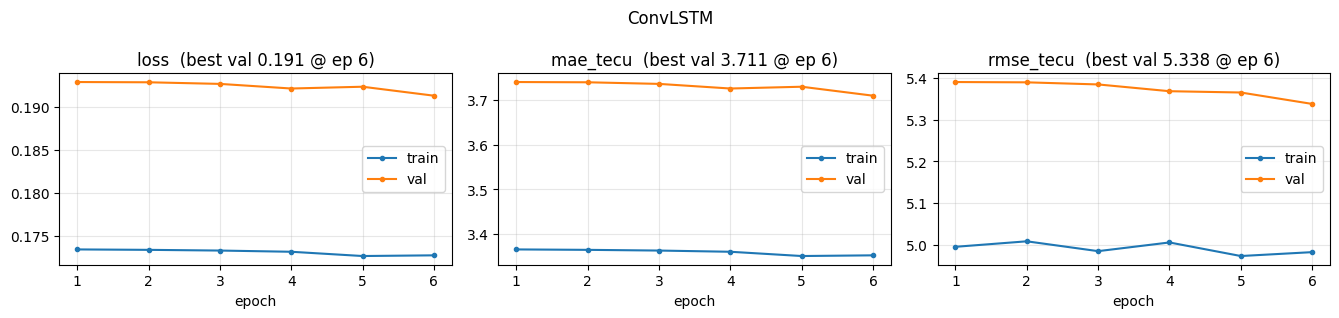

In [ ]:
def build_model(name):
    if name == "convlstm":
        return EncoderDecoderConvLSTM(nf, 1, 1, nstepsout, circular_lon, residual=convlstm_residual)
    if name == "unet":
        return UNet2D(nstepsin, nstepsout, chan=1, encoder_name=unet_encoder, encoder_weights=unet_weights,
                      encoder_depth=unet_depth, circular_lon=circular_lon, residual=unet_residual,
                      attention=unet_attention)
    raise ValueError(f"unknown model_name {name!r}")

model_label = {"convlstm": "ConvLSTM", "unet": "U-Net"}[model_name]
model = build_model(model_name)
exp = experiment(model=model, loss_fn=loss, optimizer=optimizer, lr=lr, tec_std=TEC_STD)

checkpoint = ModelCheckpoint(monitor="val_loss", mode="min", save_top_k=1)
earlystopping = EarlyStopping(monitor="val_loss", mode="min", min_delta=1e-4, patience=10)
logger = CSVLogger(log_root, name=model_name)            # {log_root}/{model_name}/version_N/metrics.csv
trainer = L.Trainer(accelerator="auto", devices=1, logger=logger,
                    callbacks=[earlystopping, checkpoint, LivePlot(title=model_label)],
                    max_epochs=max_epochs, log_every_n_steps=max(1, len(train_loader) // 2))
trainer.fit(model=exp, train_dataloaders=train_loader, val_dataloaders=val_loader)
print("Best checkpoint:", checkpoint.best_model_path, "val_loss", checkpoint.best_model_score)
print("Metrics:", os.path.join(logger.log_dir, "metrics.csv"))

In [ ]:
# Print every logged run as a per-epoch table, so the logs are kept in the saved notebook
import glob
import pandas as pd

pd.set_option("display.width", 200)
for path in sorted(glob.glob(os.path.join(log_root, "*", "version_*", "metrics.csv"))):
    df = pd.read_csv(path).groupby("epoch").first()          # train and val rows are logged separately
    cols = [c for c in df.columns if c.startswith(("train_", "val_"))]
    print(f"=== {path}  ({len(df)} epochs, best val_loss {df['val_loss'].min():.4f} "
          f"@ epoch {int(df['val_loss'].idxmin())})")
    print(df[cols].round(4).to_string())
    print()

=== lightning_logs/convlstm/version_0/metrics.csv  (20 epochs, best val_loss 0.2108 @ epoch 18)
       train_loss  train_mae_tecu  train_rmse_tecu  val_loss  val_mae_tecu  val_rmse_tecu
epoch                                                                                    
0          0.6834         13.2580          18.5367    0.6086       11.8071        16.5270
1          0.5566         10.7994          14.9734    0.5789       11.2305        15.4929
2          0.5028          9.7551          13.8641    0.5270       10.2251        14.2662
3          0.4510          8.7502          12.5391    0.4639        9.0007        12.9037
4          0.3903          7.5728          11.2897    0.3942        7.6474        11.1813
5          0.3082          5.9801           8.6216    0.3221        6.2497         8.6587
6          0.2439          4.7325           6.7573    0.2875        5.5771         7.6091
7          0.2238          4.3412           6.2282    0.2684        5.2066         7.3115
8   

# Test

In [116]:
checkpointdata = torch.load(checkpoint.best_model_path, map_location="cpu", weights_only=False)
exp.load_state_dict(checkpointdata["state_dict"])
test_metrics = trainer.test(model=exp, dataloaders=test_loader)

INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Output()

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│         test_loss         │    0.14696785807609558    │
│       test_mae_tecu       │     2.851285219192505     │
│      test_rmse_tecu       │     4.216456413269043     │
└───────────────────────────┴───────────────────────────┘

## Comparison with persistence

**Persistence** forecasts that tomorrow will repeat today: the last 12 input maps are used as the prediction.
Errors are in TECU, for each 2-hour lead time.

ConvLSTM     MAE 2.851 TECU   RMSE 4.320 TECU
Persistence  MAE 2.868 TECU   RMSE 4.358 TECU
Improvement over persistence (MAE): 0.6 %


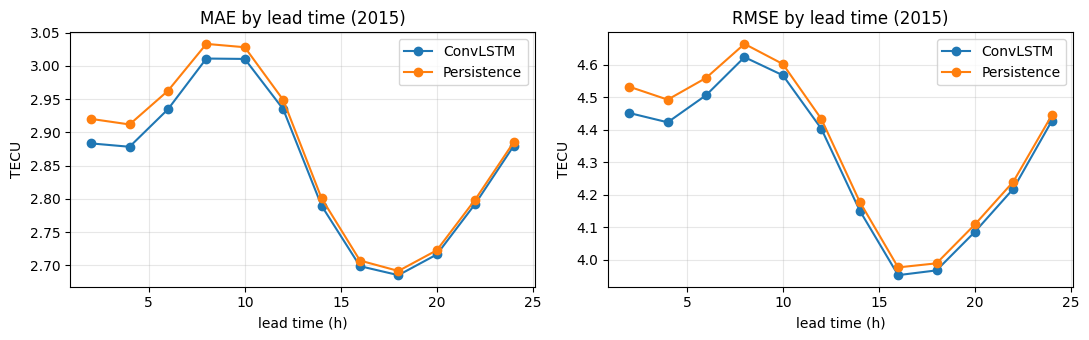

In [117]:
@torch.no_grad()
def predict(loader):
    exp.eval()
    device = exp.device
    preds, truths, persist = [], [], []
    for x, y in loader:
        preds.append(exp.model(x.to(device)).cpu().numpy())
        truths.append(y.numpy())
        persist.append(x[:, -nstepsout:].numpy())
    return [denormalize(np.concatenate(a)) for a in (preds, truths, persist)]

pred_tec, true_tec, pers_tec = predict(test_loader)      # (N, nstepsout, 1, H, W) in TECU

def errors(p, t):
    mae = np.abs(p - t).mean(axis=(0, 2, 3, 4))
    rmse = np.sqrt(((p - t) ** 2).mean(axis=(0, 2, 3, 4)))
    return mae, rmse

lead_h = (np.arange(nstepsout) + 1) * 2
res = {model_label: errors(pred_tec, true_tec), "Persistence": errors(pers_tec, true_tec)}
for name, (mae, rmse) in res.items():
    print(f"{name:12s} MAE {mae.mean():.3f} TECU   RMSE {np.sqrt((rmse ** 2).mean()):.3f} TECU")
mae_m, mae_p = res[model_label][0].mean(), res["Persistence"][0].mean()
print(f"Improvement over persistence (MAE): {100 * (1 - mae_m / mae_p):.1f} %")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for name, (mae, rmse) in res.items():
    axes[0].plot(lead_h, mae, "o-", label=name)
    axes[1].plot(lead_h, rmse, "o-", label=name)
for ax, title in zip(axes, ["MAE", "RMSE"]):
    ax.set(title=f"{title} by lead time (2015)", xlabel="lead time (h)", ylabel="TECU")
    ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

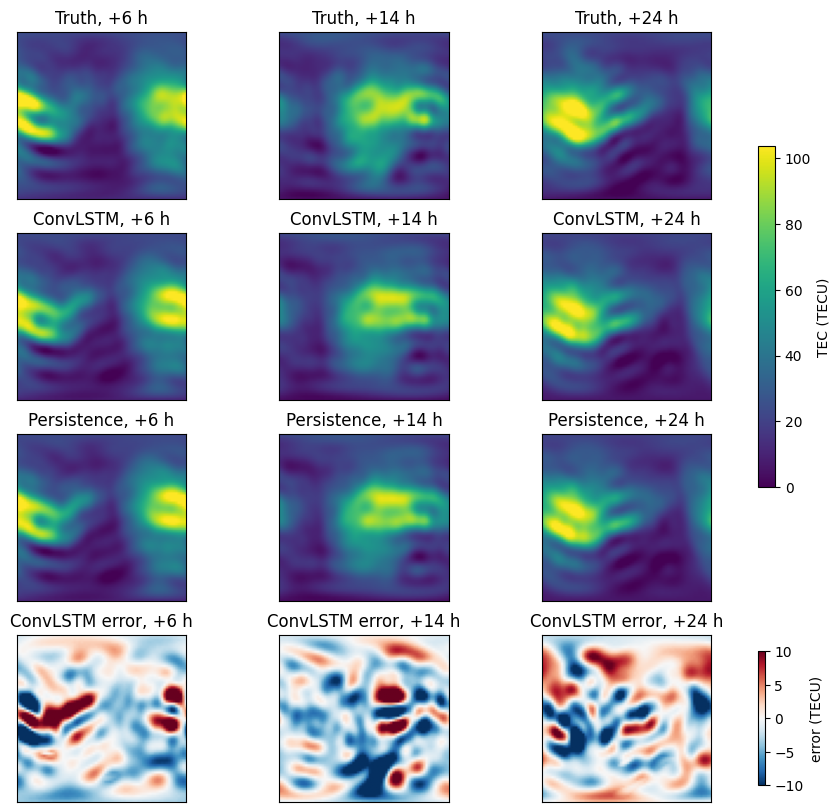

In [118]:
# Maps for one test day: truth, model, persistence and model error at three lead times
day = int(np.argmax(true_tec.mean(axis=(1, 2, 3, 4))))   # the day with the highest mean TEC
leads = [2, 6, 11]
vmax = np.percentile(true_tec[day], 99)
rows = [("Truth", true_tec), (model_label, pred_tec), ("Persistence", pers_tec)]
fig, axes = plt.subplots(4, len(leads), figsize=(4 * len(leads), 10))
for c, l in enumerate(leads):
    for r, (name, arr) in enumerate(rows):
        im = axes[r, c].imshow(arr[day, l, 0], cmap="viridis", vmin=0, vmax=vmax)
        axes[r, c].set_title(f"{name}, +{lead_h[l]} h")
    err = pred_tec[day, l, 0] - true_tec[day, l, 0]
    im_e = axes[3, c].imshow(err, cmap="RdBu_r", vmin=-10, vmax=10)
    axes[3, c].set_title(f"{model_label} error, +{lead_h[l]} h")
for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(im, ax=axes[:3].ravel().tolist(), shrink=0.6, label="TEC (TECU)")
fig.colorbar(im_e, ax=axes[3].tolist(), shrink=0.8, label="error (TECU)")
plt.show()

In [119]:
# Save the test predictions in TECU (e.g. for ionex_writer.py); the 180 deg column is added back if it was removed
out = pred_tec
if dup_meridian:
    out = np.concatenate([out, out[..., :1]], axis=-1)
fname = f"predictions_2015_{model_name}.npy"
np.save(fname, out)
print("Saved", fname, out.shape, "(N days, 12 maps, 1, lat, lon)")

Saved predictions_2015_convlstm.npy (362, 12, 1, 71, 73) (N days, 12 maps, 1, lat, lon)
